In [43]:
import joblib
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import ks_2samp, ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from sklearn.metrics import (
    roc_auc_score, roc_curve, brier_score_loss,
    mean_absolute_error, mean_squared_error,
    confusion_matrix, classification_report, precision_recall_curve
)
import shap
from itertools import combinations
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110

# Load Development, In-Time Test, and Out-of-Time Holdout datasets
dev_df = pd.read_csv("../data/model_artefacts/dev_scored_predictions.csv")
test_df = pd.read_csv("../data/model_artefacts/test_scored_predictions.csv")
oot_df = pd.read_csv("../data/model_artefacts/oot_scored_predictions.csv")

target = "possession_flag"
N_GRADES = dev_df["Risk_Grade"].nunique()
grade_names = {
    1: "Low Risk",
    2: "Moderate Risk",
    3: "High Risk",
    4: "Very High Risk",
}
grade_order = list(grade_names.values())

datasets = {
    "Development (2019-2024)": dev_df,
    "In-Time Test (2019-2024)": test_df,
    "OOT Holdout (2025-2026)": oot_df
}

for name, df in datasets.items():
    print(f"{name:<26}: {len(df):>6,} accounts | Observed Rate: {df[target].mean():.2%}")

Development (2019-2024)   : 48,838 accounts | Observed Rate: 6.80%
In-Time Test (2019-2024)  : 12,210 accounts | Observed Rate: 6.81%
OOT Holdout (2025-2026)   : 23,689 accounts | Observed Rate: 7.36%


### Rank Ordering (4-Quarter Moving Average)

If any grades cross over in a quarter, the background block for that quarter is highlighted in Red (or Amber if adjacent grades compress within 1.5%), otherwise Green.


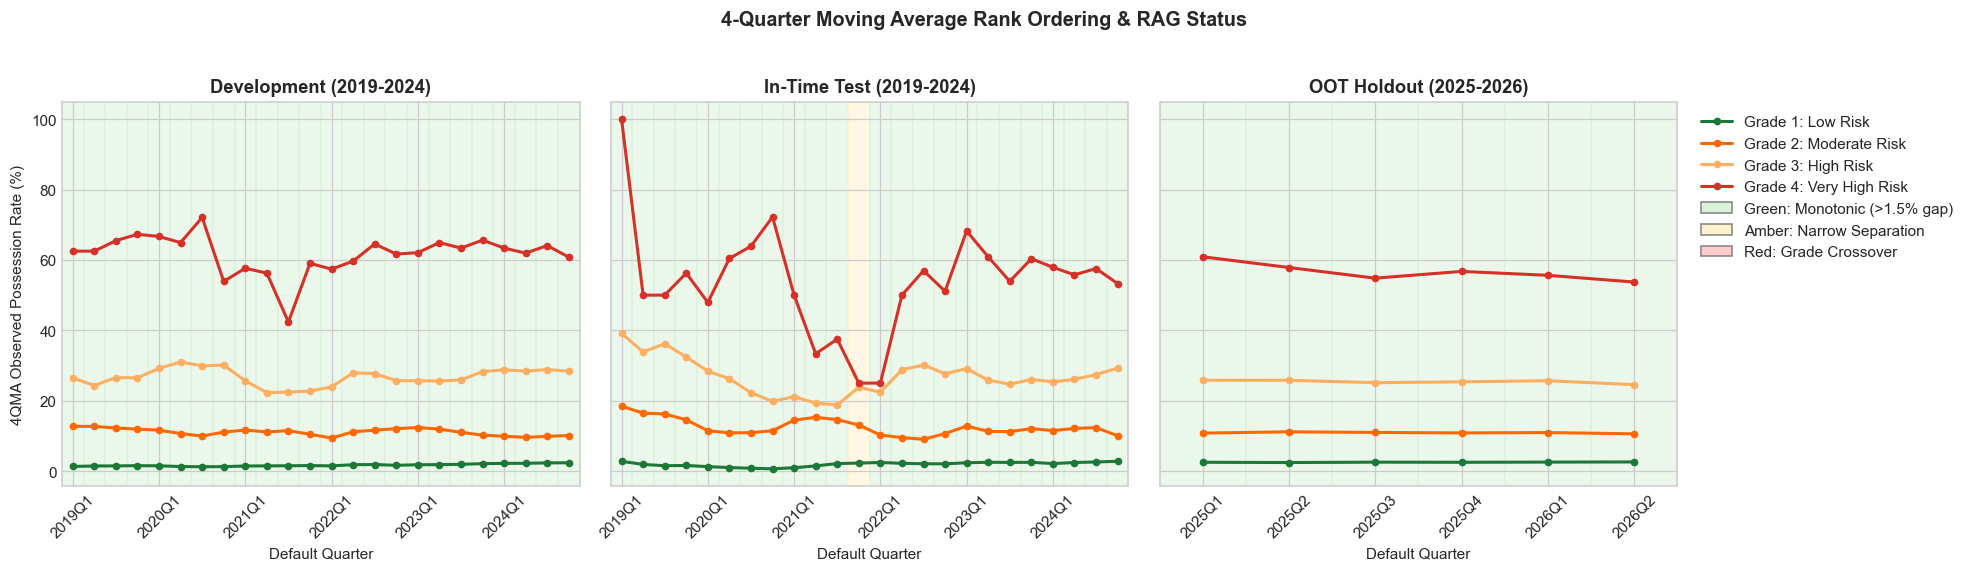

In [51]:
import os
os.makedirs("../assets/charts", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
grade_colors = ["#1b7837", "#ff6701", "#fdae61", "#d73027"] if N_GRADES == 4 else sns.color_palette("YlOrRd", N_GRADES)

for ax, (sample_name, df_sample) in zip(axes, datasets.items()):
    qtr_rates = df_sample.groupby(["default_quarter", "Risk_Grade"])[target].mean().unstack("Risk_Grade")
    qtr_4ma = qtr_rates.rolling(window=4, min_periods=1).mean() * 100
    quarters = list(qtr_4ma.index)
    
    # Assess quarterly RAG status based on grade rank-ordering and separation
    crossovers = 0
    for i, qtr in enumerate(quarters):
        rates = qtr_4ma.loc[qtr].dropna().values
        is_monotonic = np.all(np.diff(rates) > 0)
        min_gap = np.min(np.diff(rates)) if len(rates) > 1 else 0
        
        if not is_monotonic:
            rag_color = "#ffcccc"  # Red: grade crossover
            crossovers += 1
        elif min_gap < 1.5:
            rag_color = "#fff2cc"  # Amber: narrow separation (<1.5%)
        else:
            rag_color = "#d9f2d9"  # Green: distinct rank ordering
            
        ax.axvspan(i - 0.5, i + 0.5, color=rag_color, alpha=0.55, zorder=0)
    
    for g in range(1, N_GRADES + 1):
        if g in qtr_4ma.columns:
            label_name = f"Grade {g}: {grade_names.get(g, f'Grade {g}')}"
            ax.plot(range(len(quarters)), qtr_4ma[g], marker="o", markersize=4, linewidth=2, color=grade_colors[g-1], label=label_name)
            
    ax.set_title(f"{sample_name}", fontweight="bold")
    ax.set_xticks(range(0, len(quarters), max(1, len(quarters)//6)))
    ax.set_xticklabels([quarters[i] for i in range(0, len(quarters), max(1, len(quarters)//6))], rotation=45)
    ax.set_xlabel("Default Quarter")
    ax.set_xlim(-0.5, len(quarters) - 0.5)

axes[0].set_ylabel("4QMA Observed Possession Rate (%)")
rag_patches = [
    Patch(facecolor="#d9f2d9", edgecolor="grey", label="Green: Monotonic (>1.5% gap)"),
    Patch(facecolor="#fff2cc", edgecolor="grey", label="Amber: Narrow Separation"),
    Patch(facecolor="#ffcccc", edgecolor="grey", label="Red: Grade Crossover")
]
axes[2].legend(handles=axes[2].get_legend_handles_labels()[0] + rag_patches, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("4-Quarter Moving Average Rank Ordering & RAG Status", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../assets/charts/01_rank_ordering_rag.png", dpi=150, bbox_inches="tight")
plt.show()

### Concentration (HHI) & Heterogeneity

The Herfindahl-Hirschman Index (HHI) measures concentration across grades: a higher value means more accounts sit in fewer grades. With four grades, an equal split has a theoretical minimum of HHI = 0.25 ($4 \times 0.25^2$). The RAG thresholds are set above this floor at Green (HHI <= 0.38), Amber (0.38 < HHI <= 0.52), and Red (HHI > 0.52).

The table also compares observed possession rates between adjacent grades. These tests assess whether higher grades have statistically higher realised event rates; they do not test whether account volumes are equal. K-Means clusters the one-dimensional PPGD score rather than forcing equal bucket volumes, so right-skewed mortgage portfolios naturally concentrate low-risk accounts in Grade 1.

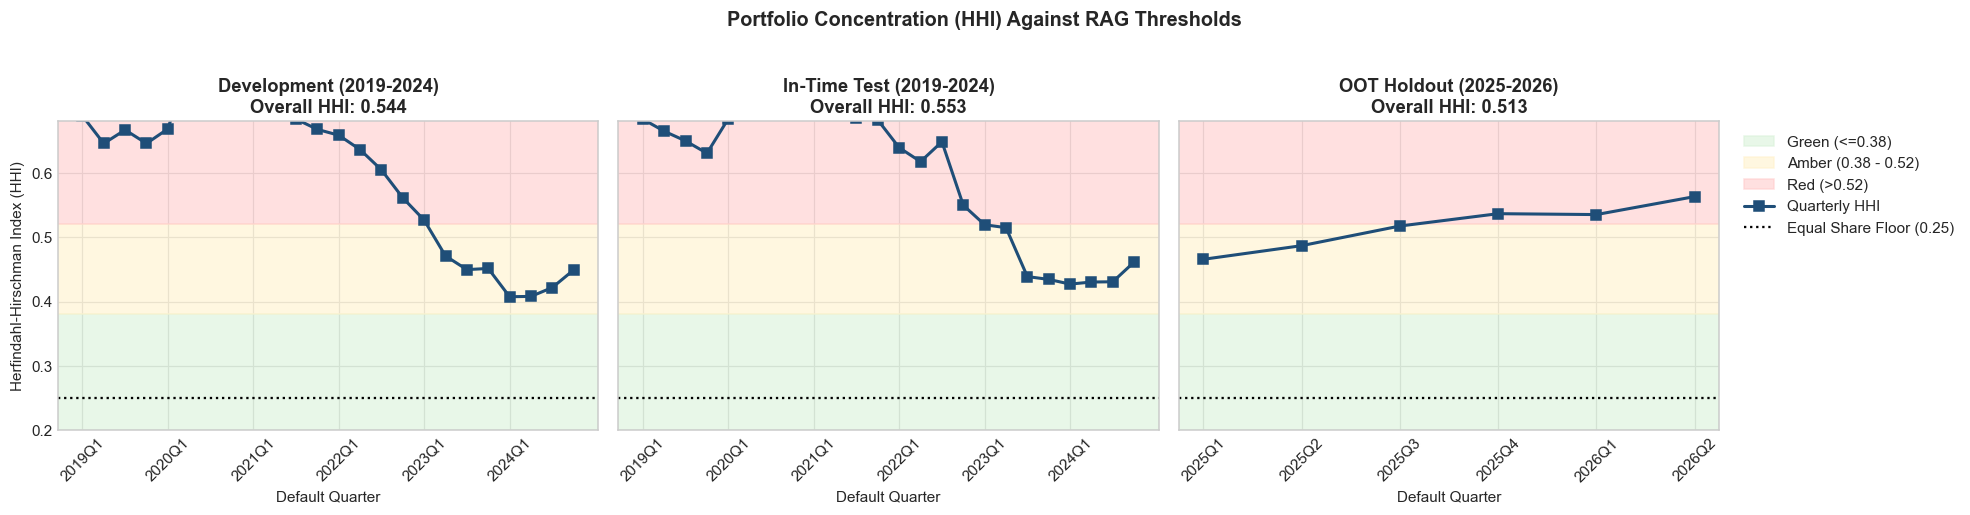


DEVELOPMENT (2019-2024) — HETEROGENEITY & CALIBRATION (HHI = 0.5441):


,Risk_Grade_Name,Volume,Share,Average_Observed_PPGD,Average_Assigned_PPGD,A_E_Ratio,Heterogeneity_p_val
0,Low Risk,34483,70.61%,0.0182,0.0182,1.00,nan
1,Moderate Risk,9740,19.94%,0.1070,0.1070,1.00,0.0000
2,High Risk,3554,7.28%,0.2774,0.2774,1.00,0.0000
3,Very High Risk,1061,2.17%,0.6287,0.6287,1.00,0.0000



IN-TIME TEST (2019-2024) — HETEROGENEITY & CALIBRATION (HHI = 0.5533):


,Risk_Grade_Name,Volume,Share,Average_Observed_PPGD,Average_Assigned_PPGD,A_E_Ratio,Heterogeneity_p_val
0,Low Risk,8710,71.33%,0.0209,0.0182,1.15,nan
1,Moderate Risk,2429,19.89%,0.1145,0.1070,1.07,0.0000
2,High Risk,815,6.67%,0.2773,0.2774,1.00,0.0000
3,Very High Risk,256,2.10%,0.5664,0.6287,0.90,0.0000



OOT HOLDOUT (2025-2026) — HETEROGENEITY & CALIBRATION (HHI = 0.5134):


,Risk_Grade_Name,Volume,Share,Average_Observed_PPGD,Average_Assigned_PPGD,A_E_Ratio,Heterogeneity_p_val
0,Low Risk,16013,67.60%,0.0255,0.0182,1.40,nan
1,Moderate Risk,5292,22.34%,0.1083,0.1070,1.01,0.0000
2,High Risk,1850,7.81%,0.2519,0.2774,0.91,0.0000
3,Very High Risk,534,2.25%,0.5562,0.6287,0.88,0.0000


In [52]:
def compute_grade_table(df_sample):
    total = len(df_sample)
    tbl = df_sample.groupby("Risk_Grade").agg(
        Volume=(target, "count"),
        Defaults=(target, "sum"),
        Average_Observed_PPGD=(target, "mean"),
        Average_Assigned_PPGD=("Grade_PPGD", "mean")
    ).reset_index()
    
    tbl["Share"] = tbl["Volume"] / total
    tbl["HHI_Part"] = tbl["Share"] ** 2
    tbl["A_E_Ratio"] = tbl["Average_Observed_PPGD"] / tbl["Average_Assigned_PPGD"]
    
    p_vals = [np.nan]
    for i in range(1, len(tbl)):
        c = np.array([tbl.loc[i, "Defaults"], tbl.loc[i-1, "Defaults"]])
        n = np.array([tbl.loc[i, "Volume"], tbl.loc[i-1, "Volume"]])
        _, pval = proportions_ztest(c, n, alternative="larger")
        p_vals.append(pval) #type:ignore
    tbl["Heterogeneity_p_val"] = p_vals
    return tbl, tbl["HHI_Part"].sum()

# Plot HHI Stability Over Time with Corrected 4-Grade RAG Zones (Dev, Test, Holdout)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (sample_name, df_sample) in zip(axes, datasets.items()):
    qtr_hhi = df_sample.groupby("default_quarter")["Risk_Grade"].apply(
        lambda s: ((s.value_counts(normalize=True)) ** 2).sum()
    )
    quarters = list(qtr_hhi.index)
    
    # RAG horizontal background blocks for 4-grade HHI (Minimum possible = 0.25)
    ax.axhspan(0.20, 0.38, color="#d9f2d9", alpha=0.6, label="Green (<=0.38)")
    ax.axhspan(0.38, 0.52, color="#fff2cc", alpha=0.6, label="Amber (0.38 - 0.52)")
    ax.axhspan(0.52, 0.70, color="#ffcccc", alpha=0.6, label="Red (>0.52)")
    
    ax.plot(range(len(quarters)), qtr_hhi.values, marker="s", color="#1f4e78", linewidth=2, label="Quarterly HHI")
    ax.axhline(1.0 / N_GRADES, color="black", linestyle=":", label=f"Equal Share Floor ({1/N_GRADES:.2f})")
    
    overall_hhi = ((df_sample["Risk_Grade"].value_counts(normalize=True)) ** 2).sum()
    ax.set_title(f"{sample_name}\nOverall HHI: {overall_hhi:.3f}", fontweight="bold")
    ax.set_xticks(range(0, len(quarters), max(1, len(quarters)//6)))
    ax.set_xticklabels([quarters[i] for i in range(0, len(quarters), max(1, len(quarters)//6))], rotation=45)
    ax.set_ylim(0.20, 0.68)
    ax.set_xlabel("Default Quarter")

axes[0].set_ylabel("Herfindahl-Hirschman Index (HHI)")
axes[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Portfolio Concentration (HHI) Against RAG Thresholds", fontsize=13, fontweight="bold", y=1.03)
plt.savefig("../assets/charts/02_hhi_concentration_rag.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()

# Display Heterogeneity & Calibration Summary Tables
for sample_name, df_sample in datasets.items():
    tbl, hhi_val = compute_grade_table(df_sample)
    tbl["Risk_Grade_Name"] = tbl["Risk_Grade"].map(grade_names)
    print(f"\n{sample_name.upper()} — HETEROGENEITY & CALIBRATION (HHI = {hhi_val:.4f}):")
    display(tbl[["Risk_Grade_Name", "Volume", "Share", "Average_Observed_PPGD", "Average_Assigned_PPGD", "A_E_Ratio", "Heterogeneity_p_val"]].style.format({
        "Share": "{:.2%}", "Average_Observed_PPGD": "{:.4f}", "Average_Assigned_PPGD": "{:.4f}",
        "A_E_Ratio": "{:.2f}", "Heterogeneity_p_val": "{:.4f}"
    }))

### Discrimination & Accuracy

MAE is the average absolute difference between the observed possession flag (0 or 1) and the predicted PPGD. Lower is better. The MAE chart uses Green (<= 0.10), Amber (> 0.10 and <= 0.20), and Red (> 0.20) to show whether performance is stable across Development, In-Time Test and OOT samples.

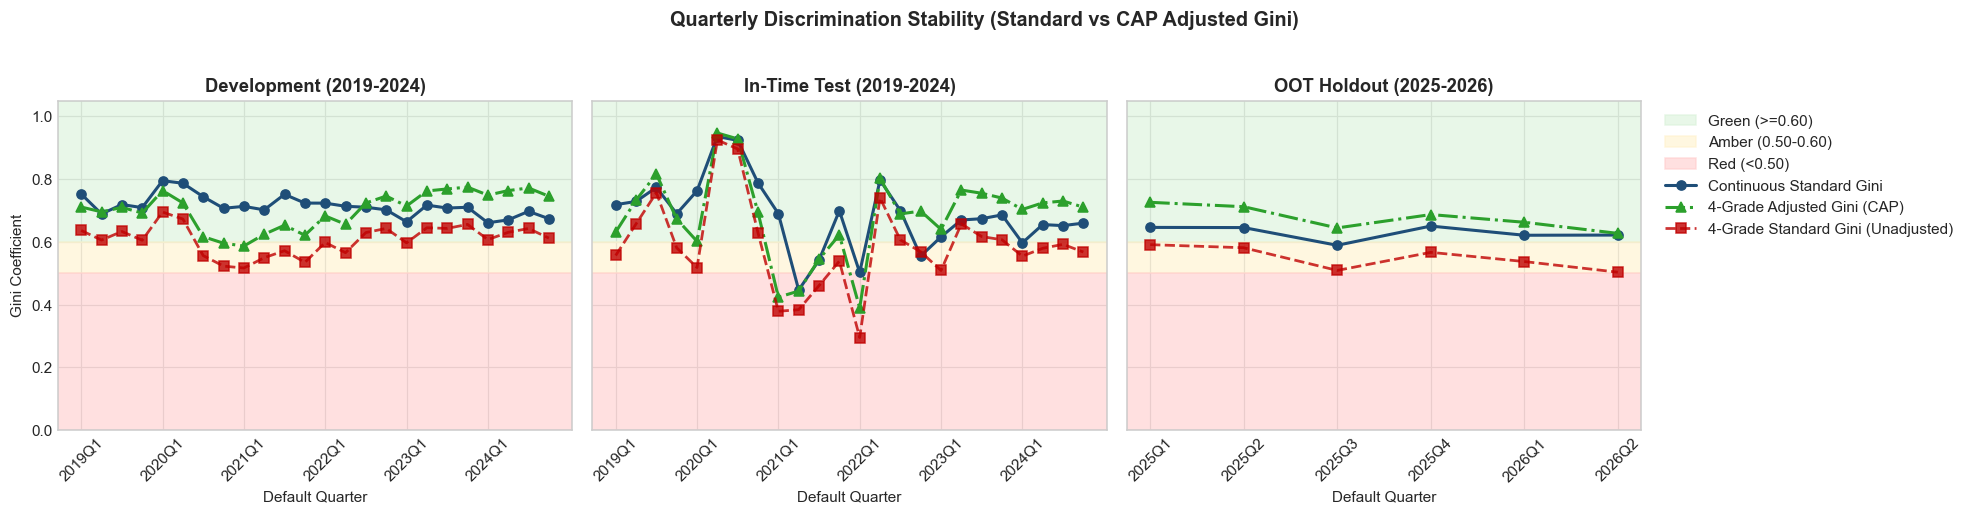

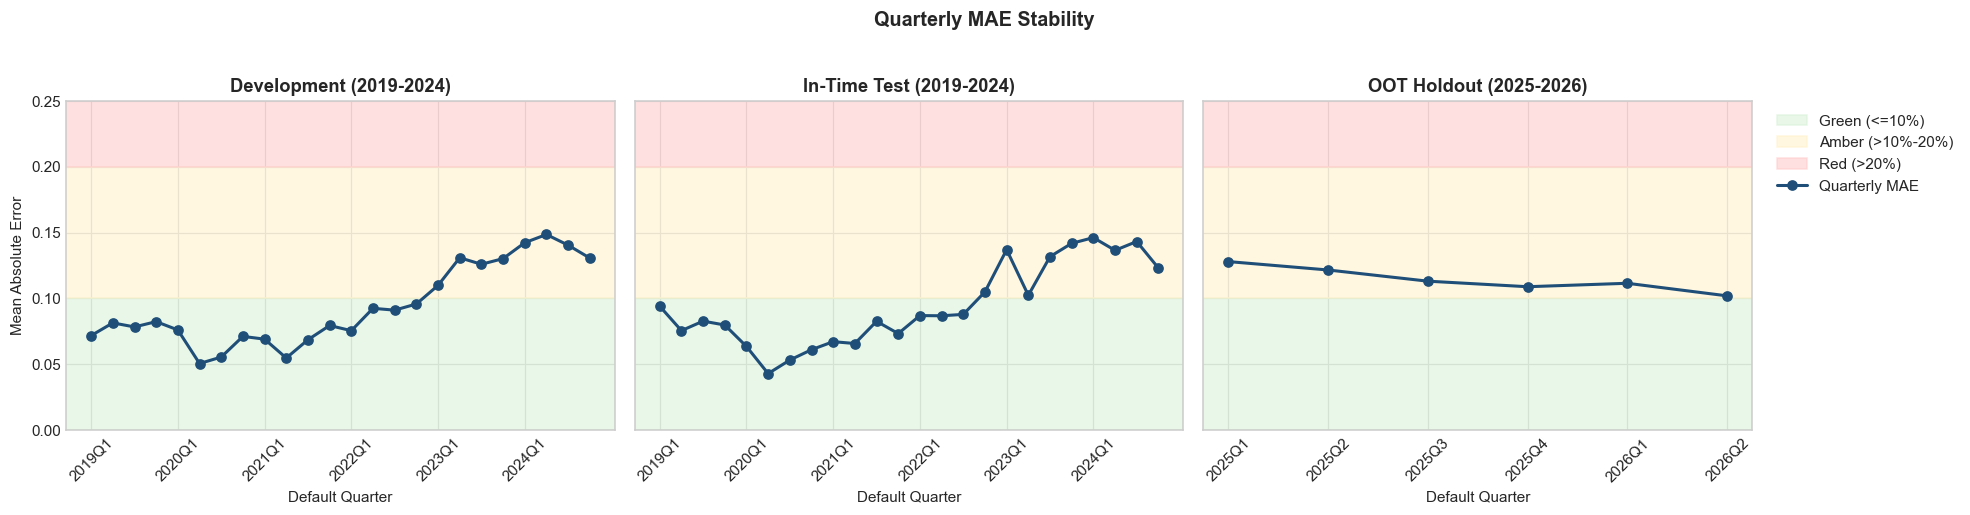

SUMMARY OF DISCRIMINATION (STANDARD & CAP-ADJUSTED GINI) & ACCURACY (MAE / RMSE / BRIER):


,Cohort,Cont_Std_Gini,Grade_Std_Gini,Grade_Adjusted_Gini,KS_Stat,MAE,RMSE,Brier_Score
0,Development (2019-2024),0.7189,0.6385,0.7448,0.5563,0.1039,0.2259,0.0511
1,In-Time Test (2019-2024),0.6813,0.6006,0.7118,0.5342,0.1045,0.2296,0.0527
2,OOT Holdout (2025-2026),0.6314,0.5548,0.6845,0.4785,0.1148,0.2406,0.0579


In [59]:
def calculate_adjusted_gini(y_true, y_scores, n_Unique_thresh=20):
    """
    Calculates Standard Gini and CAP-normalised Adjusted Gini for Low Default Portfolios (LDP)
    and discrete rating scales where tied probabilities cap the maximum achievable area.
    """
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)
    
    std_gini = 2 * roc_auc_score(y_true, y_scores) - 1
    
    # If scores are effectively continuous, bin into fine quantiles to reflect tree leaf / score granularity
    if len(np.unique(y_scores)) > n_Unique_thresh:
        binned_scores = pd.qcut(y_scores, q=n_Unique_thresh, labels=False, duplicates="drop")
    else:
        binned_scores = y_scores
        
    df_cap = pd.DataFrame({"y": y_true, "score": binned_scores})
    
    # Group by tied score buckets from highest risk to lowest risk
    bucket_stats = df_cap.groupby("score").agg(
        total=("y", "count"),
        defaults=("y", "sum")
    ).sort_index(ascending=False)
    
    total_pop = len(y_true)
    total_def = y_true.sum()
    
    # Model CAP curve coordinates
    cum_pop = np.insert(bucket_stats["total"].cumsum().values / total_pop, 0, 0.0)
    cum_def = np.insert(bucket_stats["defaults"].cumsum().values / total_def, 0, 0.0)
    model_area = np.trapezoid(cum_def, cum_pop) - 0.5
    
    # Maximum CAP achievable while preserving the grade bucket sizes:
    # within each grade, place defaults before cures. This accounts for
    # ties without reordering the grades by their realised default rates.
    perfect_within_grade = np.concatenate([
        np.r_[np.ones(int(row["defaults"])), np.zeros(int(row["total"] - row["defaults"]))]
        for _, row in bucket_stats.iterrows()
    ])
    perfect_cum_pop = np.linspace(0.0, 1.0, total_pop + 1)
    perfect_cum_def = np.insert(np.cumsum(perfect_within_grade) / total_def, 0, 0.0)
    max_achievable_area = np.trapezoid(perfect_cum_def, perfect_cum_pop) - 0.5
    
    adj_gini = model_area / max_achievable_area if max_achievable_area > 0 else std_gini
    return std_gini, adj_gini

# Quarterly Gini & Adjusted Gini Stability Across Dev, Test, and Holdout with RAG Bands
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (sample_name, df_sample) in zip(axes, datasets.items()):
    qtr_gini = []
    for qtr, grp in df_sample.groupby("default_quarter"):
        if grp[target].nunique() > 1:
            g_cont_std, _ = calculate_adjusted_gini(grp[target], grp["PPGD"])
            g_grade_std, g_grade_adj = calculate_adjusted_gini(grp[target], grp["Grade_PPGD"])
            qtr_gini.append({
                "Quarter": qtr,
                "Continuous_Std_Gini": g_cont_std,
                "Graded_Std_Gini": g_grade_std,
                "Graded_Adj_Gini": g_grade_adj
            })
    q_df = pd.DataFrame(qtr_gini).sort_values("Quarter").reset_index(drop=True)
    
    # RAG background blocks for Gini
    ax.axhspan(0.60, 1.05, color="#d9f2d9", alpha=0.6, label="Green (>=0.60)")
    ax.axhspan(0.50, 0.60, color="#fff2cc", alpha=0.6, label="Amber (0.50-0.60)")
    ax.axhspan(0.00, 0.50, color="#ffcccc", alpha=0.6, label="Red (<0.50)")
    
    ax.plot(range(len(q_df)), q_df["Continuous_Std_Gini"], marker="o", color="#1f4e78", linewidth=2, label="Continuous Standard Gini")
    ax.plot(range(len(q_df)), q_df["Graded_Adj_Gini"], marker="^", color="#2ca02c", linestyle="-.", linewidth=2, label=f"4-Grade Adjusted Gini (CAP)")
    ax.plot(range(len(q_df)), q_df["Graded_Std_Gini"], marker="s", color="#c00000", linestyle="--", linewidth=1.8, alpha=0.8, label=f"4-Grade Standard Gini (Unadjusted)")
    
    ax.set_title(f"{sample_name}", fontweight="bold")
    ax.set_xticks(range(0, len(q_df), max(1, len(q_df)//6)))
    ax.set_xticklabels([q_df["Quarter"].iloc[i] for i in range(0, len(q_df), max(1, len(q_df)//6))], rotation=45)
    ax.set_ylim(0.00, 1.05)
    ax.set_xlabel("Default Quarter")

axes[0].set_ylabel("Gini Coefficient")
axes[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Quarterly Discrimination Stability (Standard vs CAP Adjusted Gini)", fontsize=13, fontweight="bold", y=1.03)
plt.savefig("../assets/charts/03_discrimination_stability_rag.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()

# Quarterly MAE stability with the requested RAG bands
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (sample_name, df_sample) in zip(axes, datasets.items()):
    qtr_mae = (
        df_sample.groupby("default_quarter")
        .apply(lambda grp: mean_absolute_error(grp[target], grp["PPGD"]), include_groups=False) #type:ignore
        .rename("MAE")
        .reset_index()
        .sort_values("default_quarter")
        .reset_index(drop=True)
    )
    x = np.arange(len(qtr_mae))
    ax.axhspan(0.00, 0.10, color="#d9f2d9", alpha=0.6, label="Green (<=10%)")
    ax.axhspan(0.10, 0.20, color="#fff2cc", alpha=0.6, label="Amber (>10%-20%)")
    ax.axhspan(0.20, 1.00, color="#ffcccc", alpha=0.6, label="Red (>20%)")
    ax.plot(x, qtr_mae["MAE"], marker="o", color="#1f4e78", linewidth=2, label="Quarterly MAE")
    ax.set_title(f"{sample_name}", fontweight="bold")
    tick_step = max(1, len(qtr_mae) // 6)
    tick_positions = list(range(0, len(qtr_mae), tick_step))
    ax.set_xticks(tick_positions)
    ax.set_xticklabels([qtr_mae["default_quarter"].iloc[i] for i in tick_positions], rotation=45)
    ax.set_ylim(0.00, max(0.25, float(qtr_mae["MAE"].max()) * 1.15))
    ax.set_xlabel("Default Quarter")
axes[0].set_ylabel("Mean Absolute Error")
axes[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Quarterly MAE Stability", fontsize=13, fontweight="bold", y=1.03)
plt.savefig("../assets/charts/04_mae_accuracy_rag.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()

# Overall Discrimination (Standard & Adjusted Gini) & Accuracy (MAE / RMSE / Brier) Table
summary_rows = []
for sample_name, df_sample in datasets.items():
    cont_std, cont_adj = calculate_adjusted_gini(df_sample[target], df_sample["PPGD"])
    grade_std, grade_adj = calculate_adjusted_gini(df_sample[target], df_sample["Grade_PPGD"])
    ks_stat = ks_2samp(df_sample[df_sample[target]==1]["PPGD"], df_sample[df_sample[target]==0]["PPGD"])[0]
    
    summary_rows.append({
        "Cohort": sample_name,
        "Cont_Std_Gini": round(cont_std, 4),
        "Grade_Std_Gini": round(grade_std, 4),
        "Grade_Adjusted_Gini": round(grade_adj, 4),
        "KS_Stat": round(ks_stat, 4), #type:ignore
        "MAE": round(mean_absolute_error(df_sample[target], df_sample["PPGD"]), 4),
        "RMSE": round(np.sqrt(mean_squared_error(df_sample[target], df_sample["PPGD"])), 4),
        "Brier_Score": round(brier_score_loss(df_sample[target], df_sample["PPGD"]), 4)
    })

print("SUMMARY OF DISCRIMINATION (STANDARD & CAP-ADJUSTED GINI) & ACCURACY (MAE / RMSE / BRIER):")
display(pd.DataFrame(summary_rows))

### ROC Curves, Confusion Matrices & Classification Reports

The binary reports use one development-set operating point across all cohorts. The cutoff maximises F1, balancing possession precision and recall under the rare-event population rate. This is separate from K-Means: the reports classify the continuous PPGD score, while K-Means only converts that score into ordered risk grades.


CLASSIFICATION REPORT — DEVELOPMENT (2019-2024)
                precision    recall  f1-score   support

      Cure (0)       0.96      0.94      0.95     45516
Possession (1)       0.38      0.48      0.42      3322

      accuracy                           0.91     48838
     macro avg       0.67      0.71      0.69     48838
  weighted avg       0.92      0.91      0.92     48838


CLASSIFICATION REPORT — IN-TIME TEST (2019-2024)
                precision    recall  f1-score   support

      Cure (0)       0.96      0.95      0.95     11379
Possession (1)       0.36      0.43      0.39       831

      accuracy                           0.91     12210
     macro avg       0.66      0.69      0.67     12210
  weighted avg       0.92      0.91      0.91     12210


CLASSIFICATION REPORT — OOT HOLDOUT (2025-2026)
                precision    recall  f1-score   support

      Cure (0)       0.95      0.93      0.94     21945
Possession (1)       0.34      0.42      0.37      1744

    

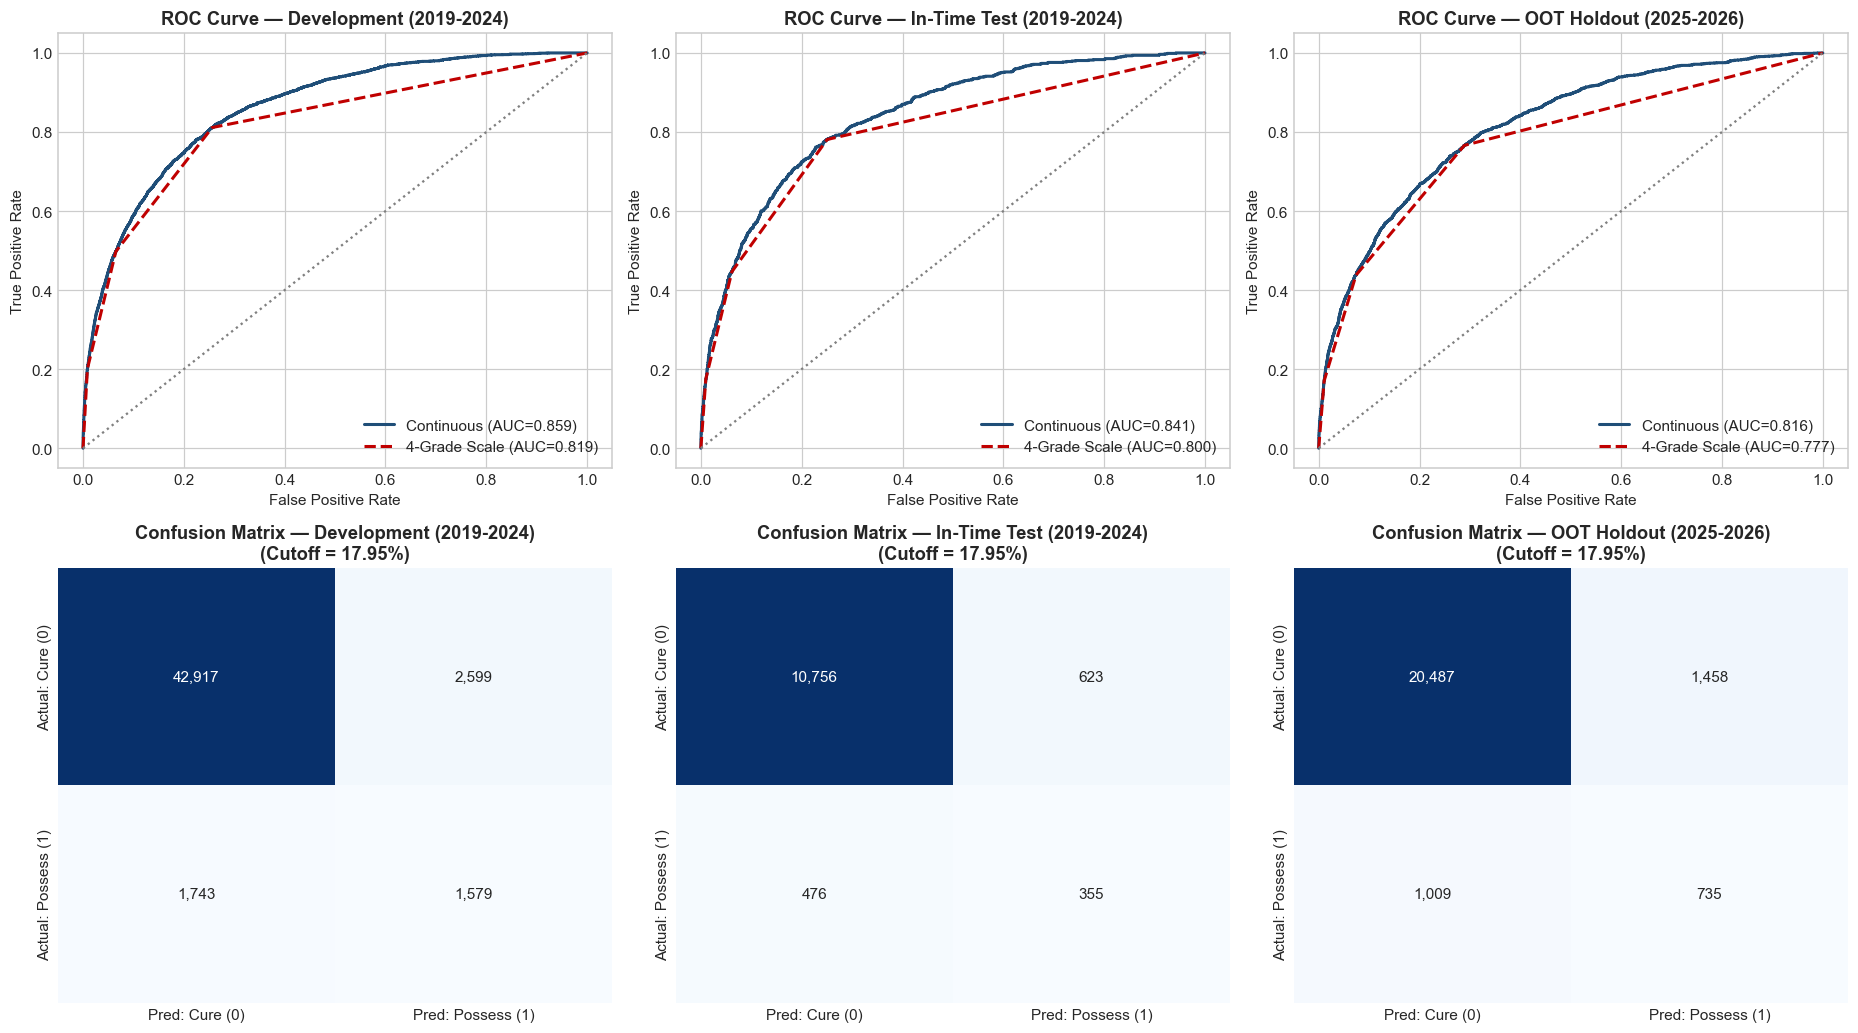

In [ ]:
# Select the same development-set F1 cutoff used in Notebook 03.
precision_dev, recall_dev, thresh_dev = precision_recall_curve(dev_df[target], dev_df["PPGD"])
f1_dev = 2 * precision_dev[:-1] * recall_dev[:-1] / np.clip(precision_dev[:-1] + recall_dev[:-1], 1e-12, None)
opt_cutoff = thresh_dev[np.nanargmax(f1_dev)]

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))

for idx, (sample_name, df_sample) in enumerate(datasets.items()):
    # ROC Curve (Continuous vs Graded)
    fpr_c, tpr_c, _ = roc_curve(df_sample[target], df_sample["PPGD"])
    fpr_g, tpr_g, _ = roc_curve(df_sample[target], df_sample["Grade_PPGD"])
    auc_c = roc_auc_score(df_sample[target], df_sample["PPGD"])
    auc_g = roc_auc_score(df_sample[target], df_sample["Grade_PPGD"])
    
    ax_roc = axes[0, idx]
    ax_roc.plot(fpr_c, tpr_c, color="#1f4e78", linewidth=2, label=f"Continuous (AUC={auc_c:.3f})")
    ax_roc.plot(fpr_g, tpr_g, color="#c00000", linestyle="--", linewidth=2, label=f"4-Grade Scale (AUC={auc_g:.3f})")
    ax_roc.plot([0, 1], [0, 1], color="grey", linestyle=":")
    ax_roc.set_title(f"ROC Curve — {sample_name}", fontweight="bold")
    ax_roc.set_xlabel("False Positive Rate")
    ax_roc.set_ylabel("True Positive Rate")
    ax_roc.legend(loc="lower right")
    
    # Confusion Matrix
    preds_bin = (df_sample["PPGD"] >= opt_cutoff).astype(int)
    cm = confusion_matrix(df_sample[target], preds_bin)
    
    ax_cm = axes[1, idx]
    sns.heatmap(
        cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax_cm,
        xticklabels=["Pred: Cure (0)", "Pred: Possess (1)"],
        yticklabels=["Actual: Cure (0)", "Actual: Possess (1)"]
    )
    ax_cm.set_title(f"Confusion Matrix — {sample_name}\n(Cutoff = {opt_cutoff:.2%})", fontweight="bold")
    
    print(f"\n{'='*60}\nCLASSIFICATION REPORT — {sample_name.upper()}\n{'='*60}")
    print(classification_report(df_sample[target], preds_bin, target_names=["Cure (0)", "Possession (1)"]))

plt.tight_layout()
plt.show()

### Statistical Separation Between Risk Grades

A Welch two-sample t-test compares every pair using the same random sample size from each grade: 30 accounts per grade, with the same seed for reproducibility. This avoids allowing the much larger Low Risk grade to dominate significance. A small p-value indicates evidence that the two grade score distributions have different means. The table reports sample sizes, average PPGD scores, the mean difference and Cohen's d as an effect-size measure. The green/red flag indicates p < 0.05 only; practical separation should be judged using the effect size and mean difference as well. This is a supporting separation test: it complements the grade-level observed possession rates and rank ordering, rather than acting as the sole approval criterion.

In [63]:
welch_results = []
for sample_name, df_sample in datasets.items():
    for grade_a, grade_b in combinations(sorted(df_sample["Risk_Grade"].unique()), 2):
        scores_a = df_sample.loc[df_sample["Risk_Grade"] == grade_a, "PPGD"]
        scores_b = df_sample.loc[df_sample["Risk_Grade"] == grade_b, "PPGD"]
        sample_size = min(30, len(scores_a), len(scores_b))
        scores_a = scores_a.sample(n=sample_size, random_state=42)
        scores_b = scores_b.sample(n=sample_size, random_state=42)
        t_stat, p_value = ttest_ind(scores_a, scores_b, equal_var=False)
        pooled_sd = np.sqrt((scores_a.var(ddof=1) + scores_b.var(ddof=1)) / 2)
        cohen_d = (scores_b.mean() - scores_a.mean()) / pooled_sd
        welch_results.append({
            "Cohort": sample_name,
            "Grade_A": grade_names[grade_a],
            "Grade_B": grade_names[grade_b],
            "N_A": sample_size,
            "N_B": sample_size,
            "Average_PPGD_A": scores_a.mean(),
            "Average_PPGD_B": scores_b.mean(),
            "Mean_Difference": scores_b.mean() - scores_a.mean(),
            "Cohens_d": cohen_d,
            "Welch_t_stat": t_stat,
            "p_value": p_value,
            "Distinct_at_5pct": p_value < 0.05, #type:ignore
        })

welch_results_df = pd.DataFrame(welch_results)
display(welch_results_df.style.format({
    "Average_PPGD_A": "{:.4f}", "Average_PPGD_B": "{:.4f}",
    "Mean_Difference": "{:.4f}", "Cohens_d": "{:.2f}",
    "Welch_t_stat": "{:.2f}",
    "p_value": "{:.3g}",
}).applymap(
    lambda value: "background-color: #d9f2d9; color: #006100" if value else "background-color: #ffcccc; color: #9c0006",
    subset=["Distinct_at_5pct"],
))

,Cohort,Grade_A,Grade_B,N_A,N_B,Average_PPGD_A,Average_PPGD_B,Mean_Difference,Cohens_d,Welch_t_stat,p_value,Distinct_at_5pct
0,Development (2019-2024),Low Risk,Moderate Risk,30,30,0.0219,0.1024,0.0805,3.29,-12.73,3.97e-16,True
1,Development (2019-2024),Low Risk,High Risk,30,30,0.0219,0.2401,0.2182,6.82,-26.40,2.1e-25,True
2,Development (2019-2024),Low Risk,Very High Risk,30,30,0.0219,0.4628,0.4408,6.16,-23.85,3.12e-21,True
3,Development (2019-2024),Moderate Risk,High Risk,30,30,0.1024,0.2401,0.1377,3.70,-14.34,7.02e-20,True
4,Development (2019-2024),Moderate Risk,Very High Risk,30,30,0.1024,0.4628,0.3604,4.87,-18.85,9.72e-20,True
5,Development (2019-2024),High Risk,Very High Risk,30,30,0.2401,0.4628,0.2227,2.90,-11.22,8.52e-14,True
6,In-Time Test (2019-2024),Low Risk,Moderate Risk,30,30,0.0200,0.1053,0.0853,3.65,-14.13,3.23e-18,True
7,In-Time Test (2019-2024),Low Risk,High Risk,30,30,0.0200,0.2481,0.2282,5.85,-22.67,3.07e-22,True
8,In-Time Test (2019-2024),Low Risk,Very High Risk,30,30,0.0200,0.4897,0.4698,6.05,-23.42,5.99e-21,True
9,In-Time Test (2019-2024),Moderate Risk,High Risk,30,30,0.1053,0.2481,0.1428,3.36,-13.01,7.49e-17,True


### Model Explainability: Global SHAP & Local LIME Interpreters

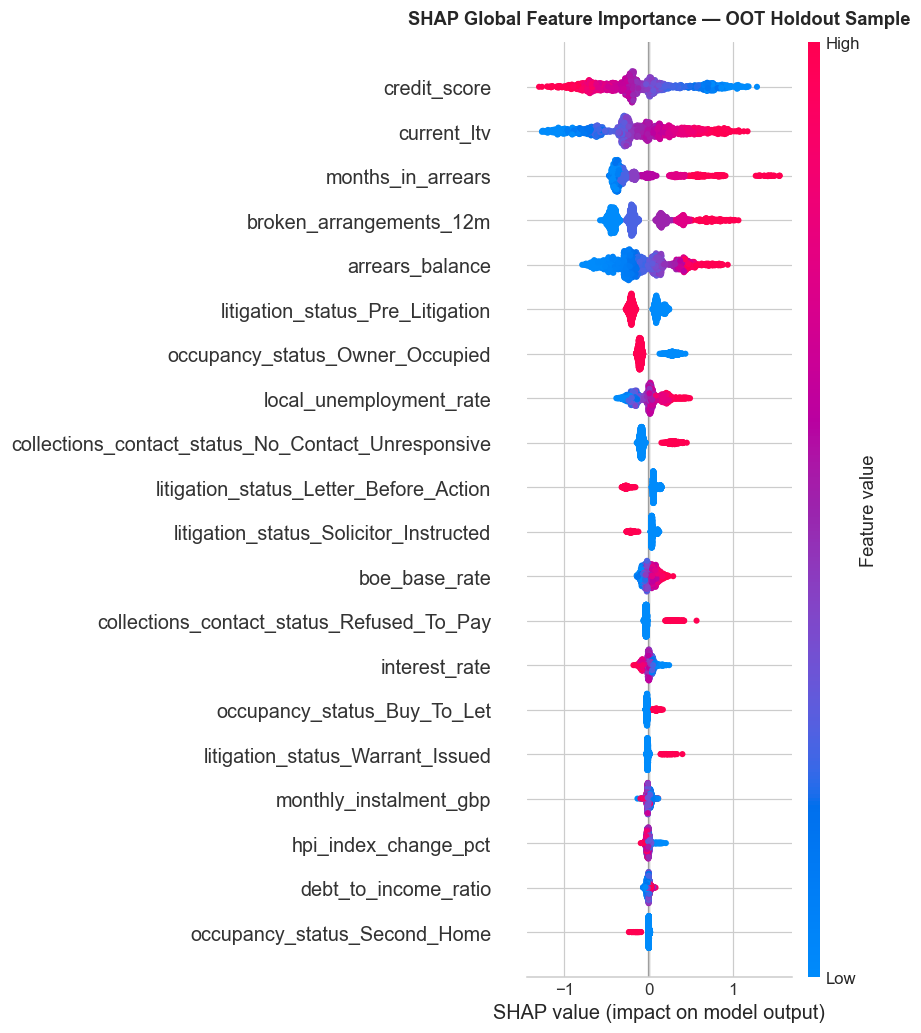

<Figure size 704x528 with 0 Axes>

Background dataset has 48838 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=48838 when initializing the masker.


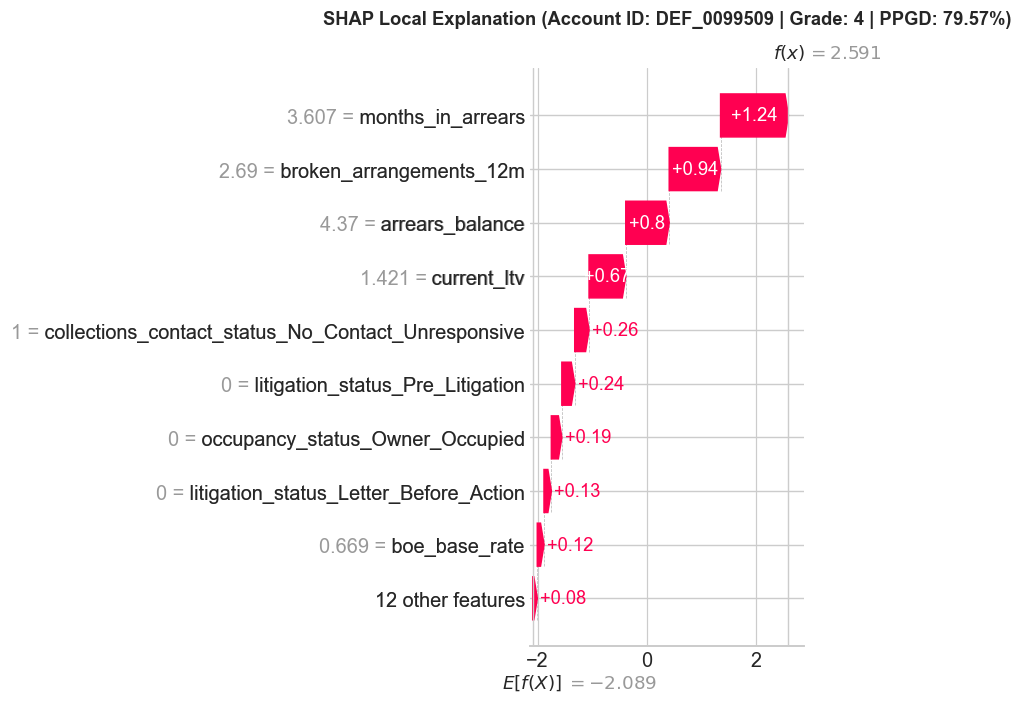

In [ ]:
# Load model, scored predictions, and preprocessed feature matrices
xgb_model = joblib.load("../data/model_artefacts/champion_xgboost_model.pkl")
oot_df = pd.read_csv("../data/model_artefacts/oot_scored_predictions.csv")
X_dev_df = pd.read_csv("../data/model_artefacts/X_dev_prep.csv")
X_oot_df = pd.read_csv("../data/model_artefacts/X_oot_prep.csv")

# Global Explainability: SHAP Summary Plot on OOT Sample
sample_oot = X_oot_df.sample(n=min(1500, len(X_oot_df)), random_state=42)

explainer_shap = shap.TreeExplainer(xgb_model)
shap_values = explainer_shap.shap_values(sample_oot)

plt.figure(figsize=(9, 6))
plt.title("SHAP Global Feature Importance — OOT Holdout Sample", fontweight="bold", pad=12)
shap.summary_plot(shap_values, sample_oot, show=True)


# Local Explainability: SHAP Waterfall Plot for a High-Risk Account
high_risk_idx = oot_df["PPGD"].idxmax()
high_risk_instance = X_oot_df.iloc[[high_risk_idx]]

explainer_obj = shap.Explainer(xgb_model, X_dev_df)
single_exp = explainer_obj(high_risk_instance)

plt.figure(figsize=(9, 5))
shap.plots.waterfall(single_exp[0], max_display=10, show=False)
plt.title(f"SHAP Local Explanation (Account ID: {oot_df.loc[high_risk_idx, 'account_id']} | "
          f"Grade: {oot_df.loc[high_risk_idx, 'Risk_Grade']} | PPGD: {oot_df.loc[high_risk_idx, 'PPGD']:.2%})", 
          fontweight="bold", pad=12)
plt.savefig("../assets/charts/05b_SHAP_local.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()